# 04 — Sensitivity maps and array scaling

The source electron rate scales exactly as $10^{-0.4 m}$ with magnitude, so the ETC can evaluate
the SNR on a (magnitude, exposure time) grid without redoing the spectrum each time, and it can
solve the limiting magnitude for a given SNR and exposure analytically, bin by bin. This notebook
builds those maps for both instruments and then asks how they move with the number of telescopes,
which is still an open design choice for LFAST.

In this notebook:
1. `snr_grid()` and `plot_snr_map()`,
2. `limiting_magnitude()` and `plot_limiting_magnitude()`,
3. `exptime_vs_mag()`,
4. scaling the array: `Telescope(...)` sweeps, `plot_vs_n_telescopes()`, `equivalent_diameter_axis()`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lfast_etc import LFASTETC, Source, Telescope, Instrument, Sky, list_instruments
from lfast_etc.plotting import plot_snr_map, plot_limiting_magnitude, plot_vs_n_telescopes, equivalent_diameter_axis

plt.rcParams.update({"figure.figsize": (7, 4), "axes.titlesize": 10, "legend.fontsize": 8})

***
## 1. SNR versus magnitude and exposure time

The map is the median SNR over 500 to 650 nm. Read it along a horizontal line to see how the SNR
grows with time at fixed magnitude, or along a contour to see how much fainter a longer exposure
reaches. The magnitude of the source object does not matter here; the grid supplies it.

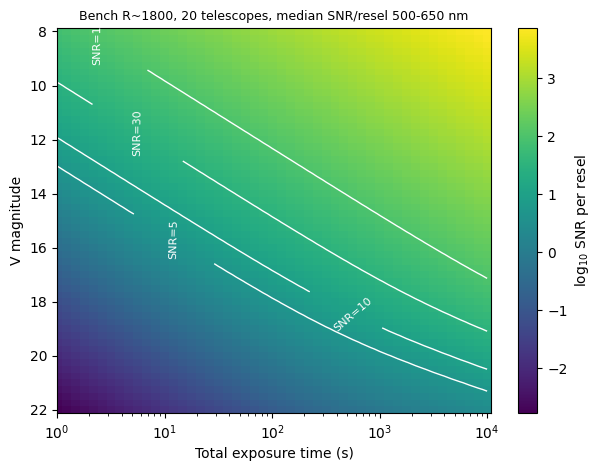

In [2]:
bench = LFASTETC("bench_r1800", n_telescopes=20)
gstar = Source.blackbody(5800, mag=0, band="V")
mags = np.linspace(8, 22, 57)
exps = np.logspace(0, 4, 49)                     # 1 s to about 3 h
snr = bench.snr_grid(gstar, mags, exps, wavelength=(500, 650))
plot_snr_map(mags, exps, snr, band="V", title="Bench R~1800, 20 telescopes, median SNR/resel 500-650 nm");

Where the contours are straight lines of slope $-2.5$ mag per decade of time the measurement is
photon limited by the star. They bend at the faint end where sky and read noise enter and the gain
per unit time slows down. Following the SNR = 10 contour, a V ~ 18.9 star reaches it in 15 min; the
gain drops from 2.5 mag per decade at the bright end to 1.5 mag between 1000 and 10,000 s.

Same map for CSHELL in its R = 18,000 mode, for one echelle setting centred on 1.555 um. The grid
starts at 8 s because that is the shortest Fowler-sampled read for which the quoted read noise
applies.

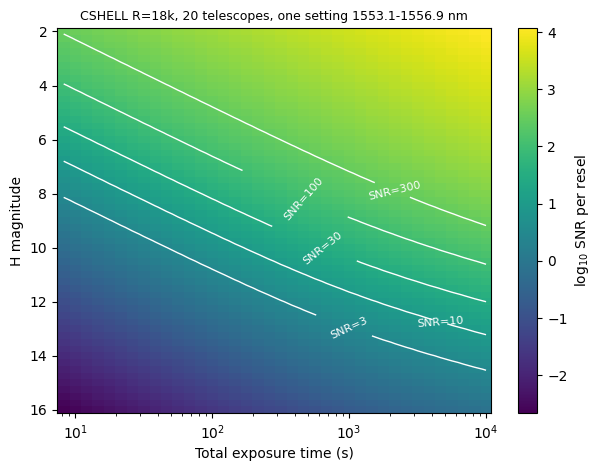

In [3]:
cs = Instrument.from_preset("cshell_r18000")
lo, hi = cs.setting_window(1555.0)
cshell = LFASTETC(cs, n_telescopes=20, wavelength_min_nm=lo, wavelength_max_nm=hi)
kstar = Source.blackbody(4500, mag=0, band="H")
mags_h = np.linspace(2, 16, 57)
exps_h = exps[exps >= cshell.instrument.min_exptime]
snr_h = cshell.snr_grid(kstar, mags_h, exps_h, wavelength=(lo, hi))
plot_snr_map(mags_h, exps_h, snr_h, band="H", levels=(3, 10, 30, 100, 300),
             title=f"CSHELL R=18k, 20 telescopes, one setting {lo:.1f}-{hi:.1f} nm");

***
## 2. Limiting magnitude

`limiting_magnitude(source, exptime, snr, wavelength)` solves for the magnitude that reaches the
target SNR; with a `(lo, hi)` window it is the median over that window, with a single wavelength
it is that bin. `plot_limiting_magnitude` does it bin by bin across the band. For the Bench the
curve follows the throughput: deepest in the red, about a magnitude shallower at 420 nm. The spikes
are the night-sky emission lines.

Bench, SNR 10 in 900 s, median over 500-650 nm: V < 18.85


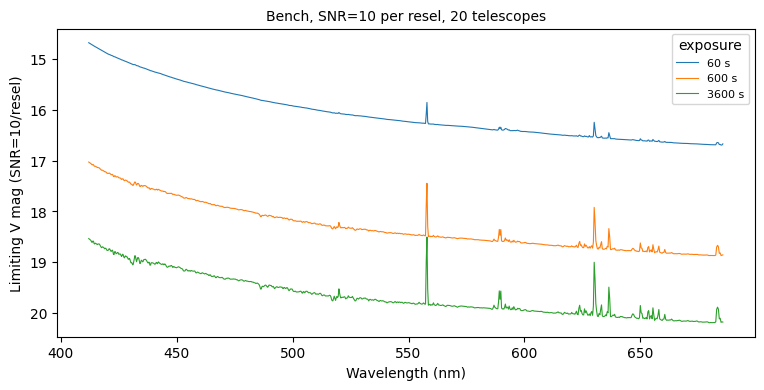

In [4]:
print(f"Bench, SNR 10 in 900 s, median over 500-650 nm: V < {bench.limiting_magnitude(gstar, 900, 10, wavelength=(500, 650)):.2f}")
fig, ax = plt.subplots(figsize=(9, 4))
plot_limiting_magnitude(bench, gstar, exptimes=[60, 600, 3600], snr=10, ax=ax)
ax.set_title("Bench, SNR=10 per resel, 20 telescopes");

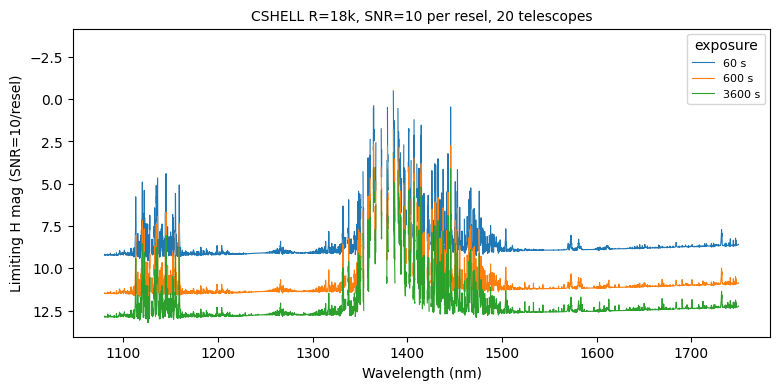

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
full = LFASTETC("cshell_r18000", n_telescopes=20)   # the whole CSHELL range, many echelle settings
plot_limiting_magnitude(full, kstar, exptimes=[60, 600, 3600], snr=10, ax=ax)
ax.set_title("CSHELL R=18k, SNR=10 per resel, 20 telescopes");

Each wavelength in the CSHELL plot is what one echelle setting would give; the curve is not a
single exposure. The gaps between 1.36 and 1.42 um are bins where $K_{opt}$ is zero in the water
band, and the ETC returns NaN there rather than a number.

***
## 3. Exposure time versus magnitude at fixed SNR

The most compact way to read off survey speed. The dashed line is one hour.

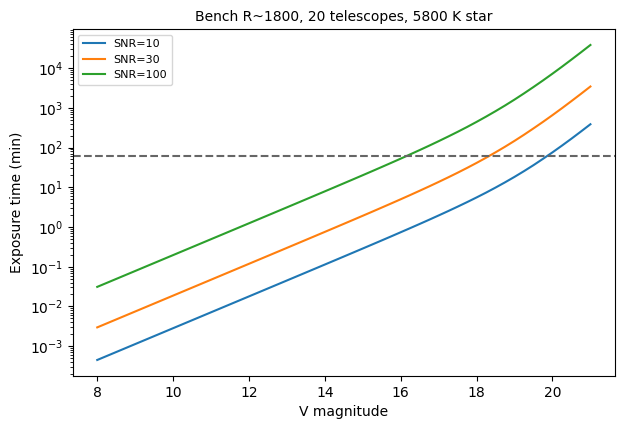

In [6]:
mags = np.linspace(8, 21, 53)
fig, ax = plt.subplots(figsize=(7, 4.5))
for snr_t in (10, 30, 100):
    t = bench.exptime_vs_mag(gstar, mags, snr=snr_t, wavelength=(500, 650))
    ax.plot(mags, t / 60, label=f"SNR={snr_t}")
ax.set_yscale("log"); ax.set_xlabel("V magnitude"); ax.set_ylabel("Exposure time (min)")
ax.axhline(60, color="0.4", ls="--"); ax.legend(); ax.set_title("Bench R~1800, 20 telescopes, 5800 K star");

***
## 4. Scaling the number of telescopes

The 18 um fibers go through a 20-to-1 combiner. Within one array both $N_*$ and $N_{sky}$ grow with
$N$ while the detector terms do not, so the gain is better than $\sqrt{N}$ whenever read noise or
dark current matter. Beyond 20 telescopes the ETC assumes one combiner input per 20 telescopes,
co-added incoherently (`telescopes_per_input=20`); the dotted curve is an idealised single
combiner for comparison. The 50 um fiber bypasses the combiner, so each telescope yields a spectrum
and the SNR grows as $\sqrt{N}$, but it couples about twice as much point-source light and admits
a 7.7 times larger patch of sky. The nominal 20-telescope prototype and the 100- and 200-telescope
upgrade options are marked; `equivalent_diameter_axis` adds the single-dish diameter with the same
collecting area on top.

> ✏️ **Before you run the next cell:** at 900 s and SNR 10, how many magnitudes deeper is 200 telescopes than 20 for the Bench? (The collecting area alone would give 2.5 mag.) Write your guess down (or put it in the room poll), then run.

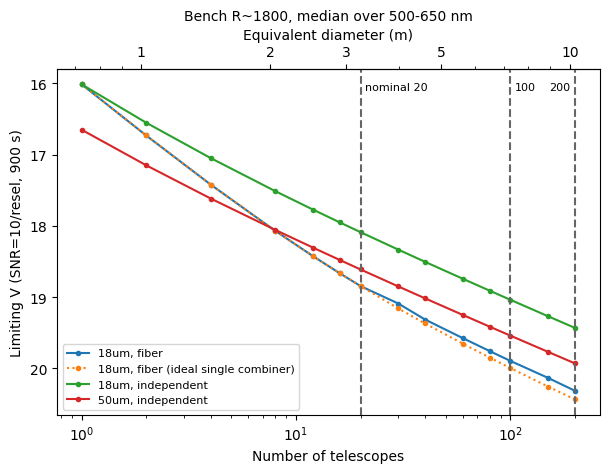

In [7]:
ns = np.array([1, 2, 4, 8, 12, 16, 20, 30, 40, 60, 80, 100, 150, 200])
configs = (("18um", "fiber", 20), ("18um", "fiber", None), ("18um", "independent", 20), ("50um", "independent", 20))
fig, ax = plt.subplots(figsize=(7, 4.5))
for fiber, combine, tpi in configs:
    lim = [LFASTETC("bench_r1800", telescope=Telescope(n_telescopes=int(n), fiber=fiber, combine=combine, telescopes_per_input=tpi))
           .limiting_magnitude(gstar, exptime=900, snr=10, wavelength=(500, 650)) for n in ns]
    ax.plot(ns, lim, marker="o", ms=3, ls=":" if tpi is None else "-",
            label=f"{fiber}, {combine}" + (" (ideal single combiner)" if tpi is None else ""))
ax.set_xscale("log"); ax.invert_yaxis()
ax.set_xlabel("Number of telescopes"); ax.set_ylabel("Limiting V (SNR=10/resel, 900 s)")
for n, txt, ha in ((20, "nominal 20", "left"), (100, "100", "left"), (200, "200", "right")):
    ax.axvline(n, color="0.4", ls="--"); ax.text(n * 1.05 if ha == "left" else n / 1.05, ax.get_ylim()[1] + 0.3, txt, fontsize=8, ha=ha)
ax.legend(); ax.set_title("Bench R~1800, median over 500-650 nm")
equivalent_diameter_axis(ax);

The same comparison for CSHELL, where the 22 e$^-$ read noise and the 0.5 e$^-$/s dark current,
both over a 36-pixel extraction aperture, are large, shows the fiber combiner mattering more.

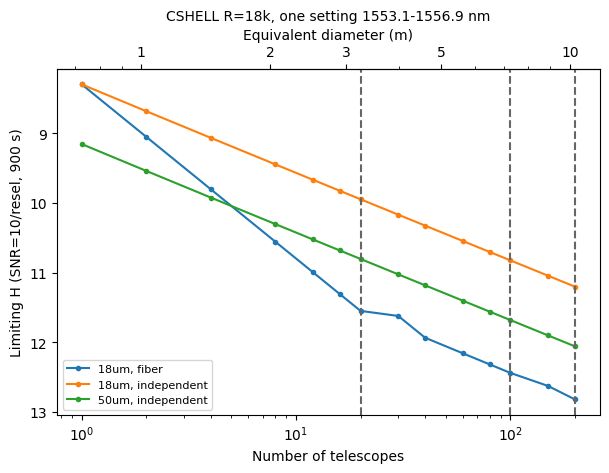

In [8]:
fig, ax = plt.subplots(figsize=(7, 4.5))
for fiber, combine in (("18um", "fiber"), ("18um", "independent"), ("50um", "independent")):
    lim = [LFASTETC("cshell_r18000", telescope=Telescope(n_telescopes=int(n), fiber=fiber, combine=combine),
                    wavelength_min_nm=lo, wavelength_max_nm=hi).limiting_magnitude(kstar, 900, 10)
           for n in ns]
    ax.plot(ns, lim, marker="o", ms=3, label=f"{fiber}, {combine}")
ax.set_xscale("log"); ax.invert_yaxis()
ax.set_xlabel("Number of telescopes"); ax.set_ylabel("Limiting H (SNR=10/resel, 900 s)")
for n in (20, 100, 200):
    ax.axvline(n, color="0.4", ls="--")
ax.legend(); ax.set_title(f"CSHELL R=18k, one setting {lo:.1f}-{hi:.1f} nm")
equivalent_diameter_axis(ax);

For the common case of one configuration and several exposure times there is a one-call helper,
`plot_vs_n_telescopes`. You pass a function that builds the ETC for a given $N$, so you decide the
fiber, the combiner and the bandpass.

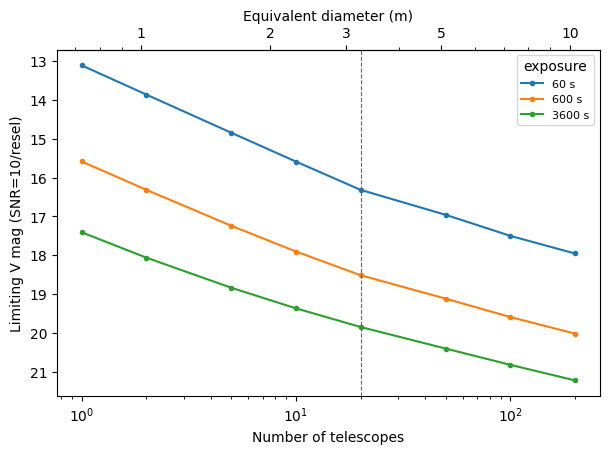

In [9]:
plot_vs_n_telescopes(lambda n: LFASTETC("bench_r1800", n_telescopes=n), gstar,
                     ns=[1, 2, 5, 10, 20, 50, 100, 200], exptimes=[60, 600, 3600], snr=10, wavelength=(500, 650));

> 🤖 **Ask Jupyter AI:** *Redo the Bench sensitivity map for a 3500 K star normalised in I instead of V. Which contour moves most, and why does the normalising band matter here?*
>
> Then: add n_exp=10 to snr_grid. Where on the map does the extra read noise show?

***
## Summary

```python
snr = etc.snr_grid(src, mags, exptimes, wavelength=(500, 650)); plot_snr_map(mags, exptimes, snr, band="V")
etc.limiting_magnitude(src, exptime=900, snr=10, wavelength=(500, 650))
plot_limiting_magnitude(etc, src, exptimes=[60, 600, 3600], snr=10)
etc.exptime_vs_mag(src, mags, snr=30, wavelength=(500, 650))
plot_vs_n_telescopes(lambda n: LFASTETC("bench_r1800", n_telescopes=n), src, ns, exptimes, snr=10)
equivalent_diameter_axis(ax)
```

Now pick an exercise from the [README](README.md).